# PD–FUT attribution: why does the BVOC response reverse?

The maps in `radiative_forcing.ipynb` and `bvoc-soa-cloud-interactions.ipynb` show *what* changes. This notebook asks *why* the response differs between PD and FUT, and how much of it belongs to the intended experiment.
Code: `boreal_forest_expansion.plotting.forcing_maps` (section "Regional and monthly diagnostics").

**Meeting set:** figures A (radiative budget, 3 contrasts), B (origin of the emission perturbation), C (seasonal BVOC → SOA → cloud → SW chain).

### What each run is (verified in the case namelists, 2026-10-25)
| Alias | Case | BVOC emissions |
|---|---|---|
| CTRL_PD / CTRL_FUT | `NF2000…/NF2100ssp585…nudg_ctrl_f19_f19-20260925` | interactive MEGAN, all compounds |
| LCC_PD / LCC_FUT | `…nudg_lcc_f19_f19-20261005` | interactive MEGAN, all compounds |
| LCC_PD_fBVOC | `NF2000…nudg_lcc_fBVOC_f19_f19-20261008` | **ISOP + MTERP only**, prescribed from `ems_NF2000…ctrl…-20260925_2001-2009_SF{ISOP,MTERP}.nc` (CTRL_PD 2001–2009 half-hourly climatology); `megan_specifier=''` → no other MEGAN compounds |
| LCC_FUT_fBVOC | `NF2100ssp585…nudg_lcc_fBVOC_f19_f19-20261009` | the **same CTRL_PD climatology**, dates relabelled to 2100 (`…_on_yr2100_…`); no other MEGAN compounds |

So **LCC − fBVOC** = (interactive LCC emissions of all compounds) − (CTRL_PD ISOP+MTERP climatology, nothing else). In FUT this includes the climate/CO₂-driven emission change, and in both periods it includes all non-terpene MEGAN compounds.
**fBVOC − CTRL** = the land-cover change with emissions held at CTRL_PD ISOP/MTERP (and no other MEGAN compounds) = the non-BVOC (biogeophysical) part plus the effect of the missing compounds.

### Conventions
- All differences are **paired by year** (nudged runs share the winds): 9 years, 2001–2009.
- **"±" = 95 % t-interval across the yearly regional means** (not the SD, not the SE). Shaded bands in monthly plots: the same, per month.
- Map hatching (other notebooks) = **not significant**: paired t-test per cell, Benjamini–Hochberg FDR α = 0.10 over the cells ≥45°N.
- Regions: ≥45°N = all cells (land + ocean), area-weighted; modified cells = land cells whose PFTs changed (`modified_cells.nc`); unmodified land ≥45°N = other land cells ≥45°N. CLM fields: area × landfrac weights.
- A precise mean does not remove systematic bias from the setup (spin-up offset in LCC − CTRL; emission reference in fBVOC).
- **Provisional:** CTRL `-20260925` is superseded by `-20261023`; redo on the 2001–2014 set.


## Findings (2026-10-26, from the outputs below; (a) = number read from the tables, (b) = interpretation)
**1. The FUT cancellation is in the cloud term (a).** ≥45°N NET, FUT: LCC−CTRL +0.27 = fBVOC−CTRL **+0.97** (cloud +1.05, clear-clean −0.04) + LCC−fBVOC **−0.70** (cloud −0.83). PD: +0.24 = +0.12 (clear-clean +0.31, cloud −0.19) + +0.13. The surface albedo proxy is similar in fBVOC−CTRL PD/FUT (+0.46 / +0.41), so the albedo does **not** explain the +0.97. Tables: `results/tables/radiative_budget_3contrasts_2001_2009.csv`.
**2. FUT: the emission perturbation in LCC−fBVOC is mostly the emission reference, not the land-cover change (a+b).** LCC_FUT − LCC_FUT_fBVOC: isoprene +7.4 / monoterpene +15 Tg yr⁻¹ in the modified cells (and +2.5–3.2 / +6–6.6 in unmodified land), while LCC_FUT − CTRL_FUT is **negative** (−0.2 / −1.2 modified, −2.2 / −2.5 unmodified). So LCC_FUT emits far more than the CTRL_PD climatology fBVOC_FUT receives (b: the climate/CO₂ response of emissions), and the matching cloud brightening (C: SOA +4.7 mg m⁻², N_AER +400 cm⁻³, droplets +5.7 cm⁻³, radius −0.4 µm, SW cloud term −2.5 W m⁻² in July) appears as −0.83 in LCC−fBVOC and as +1.05 (missing brightening) in fBVOC−CTRL. **The FUT BVOC contrast mainly measures "FUT emissions vs PD emissions", as expected from the setup.** `emission_origin_annual_2001_2009.csv`.
**3. FUT LAI/emission deficit in unmodified land is the land-state legacy, stable in time (a+b).** LCC_FUT − CTRL_FUT: LAI −0.25…−0.5 and γ_LAI −0.1…−0.17 in unmodified cells all year; early (2001–04) ≈ late (2006–09) → no recovery within the run (b: CO₂-bug spin-up legacy, see CLAUDE.md).
**4. The seasons line up (a).** In FUT the emission, SOA, aerosol, droplet and SW-cloud anomalies all peak in June–August, at the insolation maximum.
**5. PD: emissions up, SOA/N_AER down is a setup offset, not precursor timing (a+b).** In all four boxes LCC−fBVOC and LCC−CTRL have the **same** emission change (fBVOC uses CTRL_PD emissions), but only LCC−fBVOC has lower SOA (≈ −0.06 mg m⁻² in winter) and N_AER (E Canada/Europe −100 cm⁻³ in summer) — also in **winter, when emissions are ~0**. So the PD deficit comes from something fBVOC has differently all year (b: most likely the missing non-terpene MEGAN compounds → different oxidant/sulfate chemistry); it is not SOA falling where precursors rise.
**6. Baseline (a).** CTRL_FUT vs CTRL_PD ≥45°N: SOA +191 % (ANN), JJA N_AER +26 %, CCN3 +39 %, in-cloud droplets +3 %. The FUT BVOC contrast is large relative to its fBVOC baseline (SOA +139 %, N_AER +25 %, droplets +10 %, radius −3 %) → mostly a larger perturbation, not only a more responsive background (b).
**Uncertainty:** all ± are 95 % t-intervals across the 9 paired years; section E shows the years individually. Closure: Ghan terms vs total 1e-7, contrasts 4e-4 W m⁻² (float32 rounding).


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
pd.set_option("display.width", 220, "display.max_rows", 300, "display.max_columns", 30)
START_YEAR, END_YEAR = 2001, 2009
TABLES = fm.REPO_DIR / "results" / "tables"
print(fm.BVOC_PAIRS)

{'PD': {'lcc': 'LCC_PD', 'fbvoc': 'LCC_PD_fBVOC', 'ctrl': 'CTRL_PD'}, 'FUT': {'lcc': 'LCC_FUT', 'fbvoc': 'LCC_FUT_fBVOC', 'ctrl': 'CTRL_FUT'}}


## A. Radiative budget across the three contrasts (meeting fig. 1)
LCC − CTRL = (fBVOC − CTRL) + (LCC − fBVOC), exactly, year by year. Bars: Ghan total, ARI, cloud, clear-clean (NET, SW, LW); the hatched bar is the clear-sky **surface** albedo proxy (SW), shown for orientation only: it is not a term of the TOA budget.
Rows: ≥45°N and modified cells; PD and FUT. Same masks and weights for every contrast. Closure is checked before any rounding.

In [2]:
budget = fm.radiative_budget_table(START_YEAR, END_YEAR)
budget.to_csv(TABLES / f"radiative_budget_3contrasts_yearly_{START_YEAR}_{END_YEAR}.csv", index=False)
summary = fm.summarize_years(budget, ["period", "region", "contrast", "band", "term"])
summary.to_csv(TABLES / f"radiative_budget_3contrasts_{START_YEAR}_{END_YEAR}.csv", index=False)
(summary[summary.band == "NET"]
 .pivot_table(index=["region", "period", "contrast"], columns="term", values="mean").round(3))

Closure before rounding: Ghan terms vs total 1.1e-07, contrasts 4.4e-04 W m-2


term                              clearclean  cre_clean    dir    toa
region         period contrast                                       
modified cells FUT    LCC−CTRL         0.573      0.184 -0.076  0.682
                      LCC−fBVOC        0.094     -0.889 -0.046 -0.841
                      fBVOC−CTRL       0.478      1.073 -0.029  1.522
               PD     LCC−CTRL         0.908     -0.296 -0.030  0.582
                      LCC−fBVOC        0.044      0.084 -0.000  0.127
                      fBVOC−CTRL       0.864     -0.380 -0.030  0.455
≥45°N          FUT    LCC−CTRL         0.112      0.229 -0.070  0.272
                      LCC−fBVOC        0.150     -0.826 -0.022 -0.697
                      fBVOC−CTRL      -0.038      1.055 -0.048  0.969
               PD     LCC−CTRL         0.365     -0.114 -0.009  0.242
                      LCC−fBVOC        0.054      0.072 -0.000  0.126
                      fBVOC−CTRL       0.311     -0.186 -0.009  0.116

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/radiative_budget_3contrasts_2001_2009.png


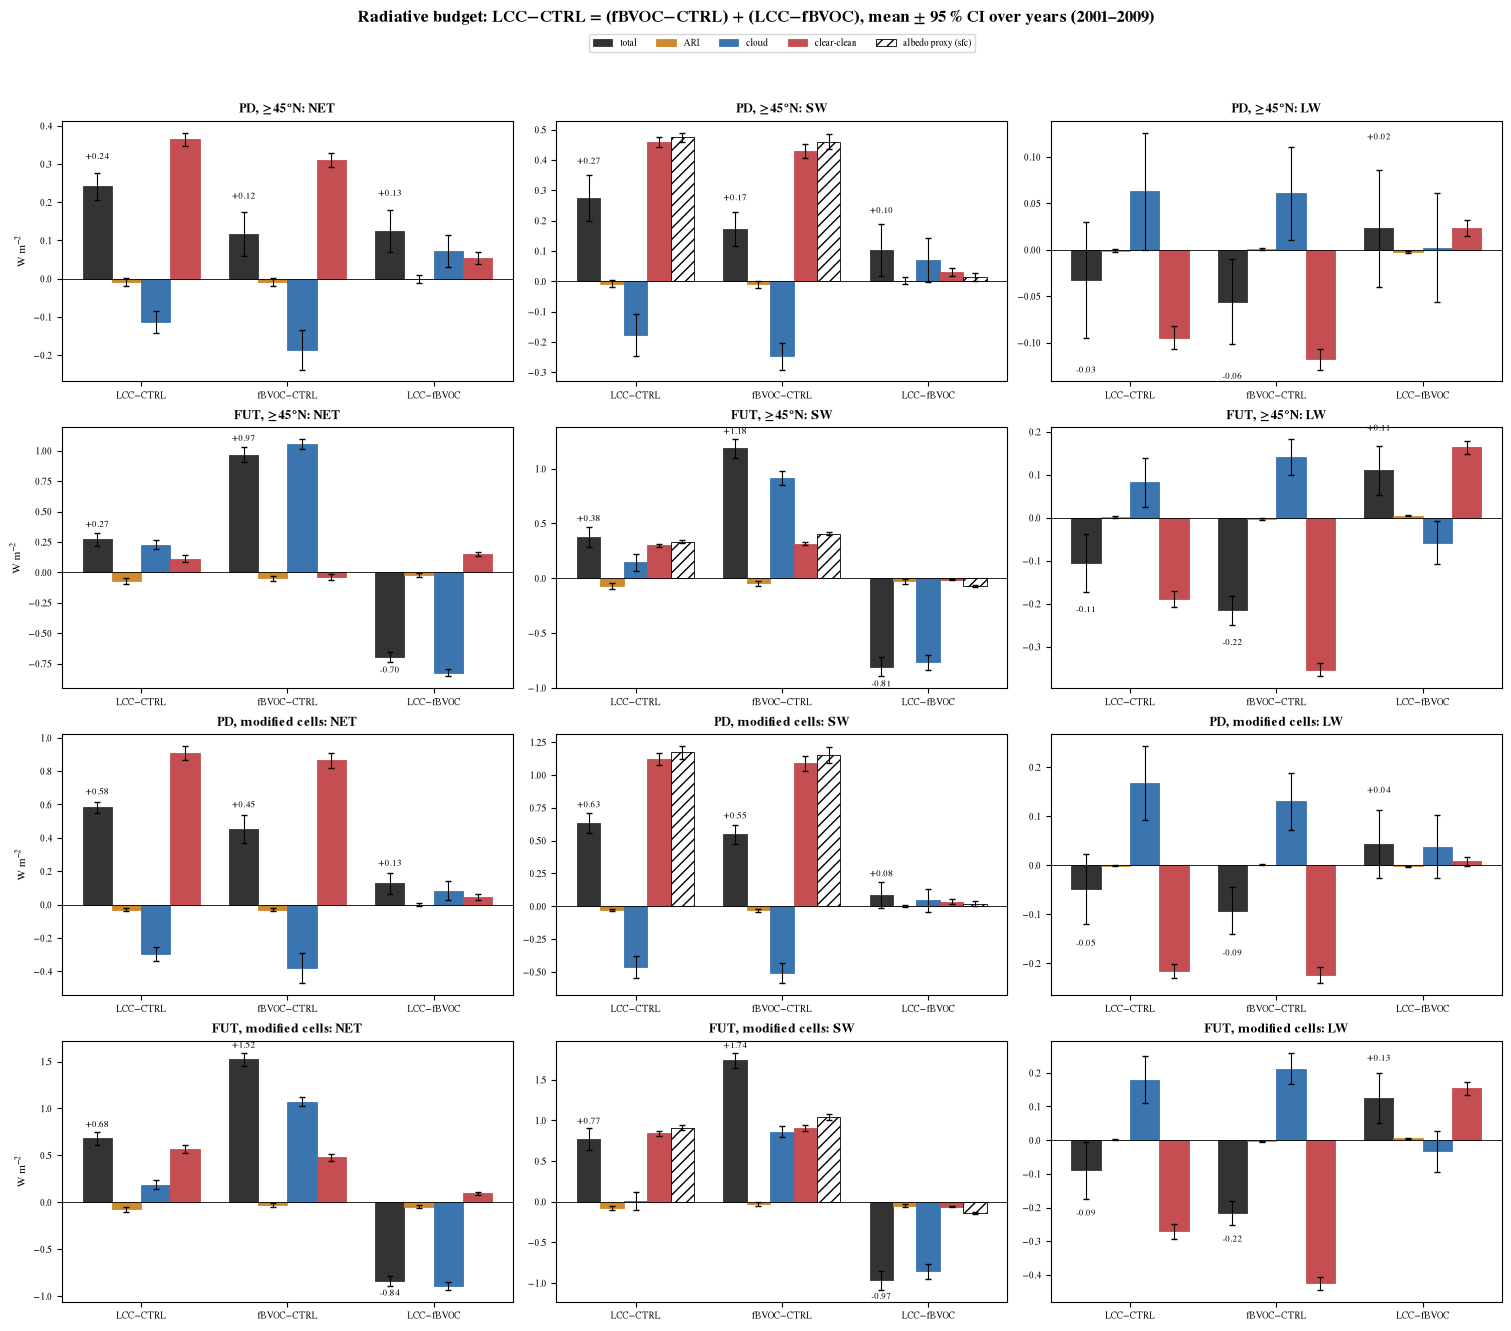

In [3]:
fig, axes = fm.make_radiative_budget_figure(budget, start_year=START_YEAR, end_year=END_YEAR)
plt.show(); plt.close(fig)

## B. Origin of the emission perturbation (meeting fig. 2)
Monthly differences of isoprene and monoterpene emission (regional **totals**, Tg month⁻¹), LAI and the MEGAN activity factors γ_isoprene and γ_LAI (grid-cell **area means** over vegetated patches, not emission-weighted), in modified vs unmodified land ≥45°N.
Solid = early years 2001–2004 (± 95 % CI), dashed = late years 2006–2009: a drift between them points to the land state still adjusting.
Vegetation and emission differences in **unmodified** cells are the direct diagnostic of a setup (spin-up) effect; atmospheric anomalies outside the modified cells are not, since the atmosphere transports and responds remotely.

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/emission_origin_monthly_2001_2009.png


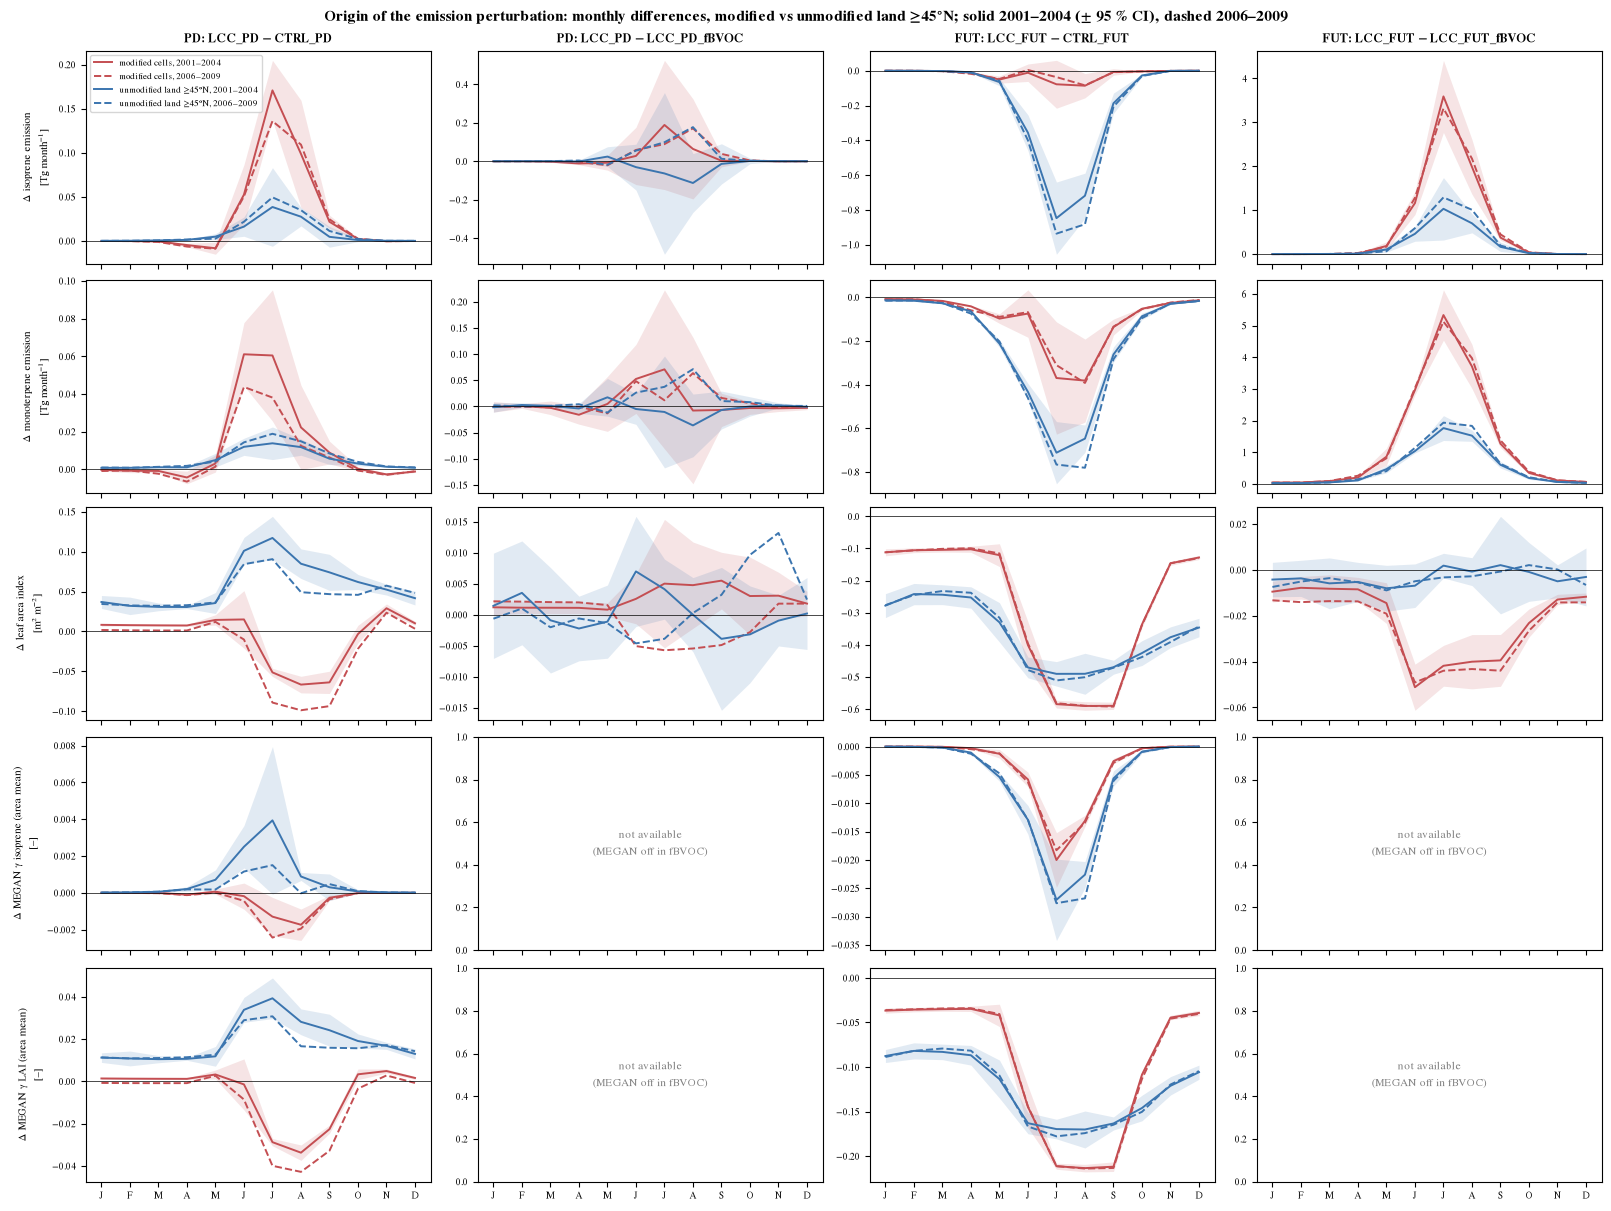

In [4]:
fig, axes = fm.make_emission_origin_figure(start_year=START_YEAR, end_year=END_YEAR)
plt.show(); plt.close(fig)

In [5]:
# Annual totals behind figure B (Tg/yr; mean over 9 years), early vs late
rows = []
for p in fm.BVOC_PAIRS:
    for lab, c1, c2 in fm.budget_contrasts(p):
        if lab == "fBVOC−CTRL":
            continue
        for region in ("modified cells", "unmodified land ≥45°N"):
            for field in ("SFISOP_Tg", "SFMTERP_Tg"):
                d = fm.monthly_difference(c1, c2, field, region, start_year=START_YEAR, end_year=END_YEAR).sum("month")
                rows.append(dict(period=p, contrast=f"{c1} − {c2}", region=region, field=field,
                                 all_years=float(d.mean()), early=float(d.sel(year=slice(*fm.EARLY_YEARS)).mean()),
                                 late=float(d.sel(year=slice(*fm.LATE_YEARS)).mean())))
emis = pd.DataFrame(rows)
emis.to_csv(TABLES / f"emission_origin_annual_{START_YEAR}_{END_YEAR}.csv", index=False)
emis.round(3)

,period,contrast,region,field,all_years,early,late
0,PD,LCC_PD − CTRL_PD,modified cells,SFISOP_Tg,0.322,0.332,0.306
1,PD,LCC_PD − CTRL_PD,modified cells,SFMTERP_Tg,0.118,0.146,0.087
2,PD,LCC_PD − CTRL_PD,unmodified land ≥45°N,SFISOP_Tg,0.111,0.095,0.125
3,PD,LCC_PD − CTRL_PD,unmodified land ≥45°N,SFMTERP_Tg,0.065,0.057,0.072
4,PD,LCC_PD − LCC_PD_fBVOC,modified cells,SFISOP_Tg,0.323,0.263,0.335
5,PD,LCC_PD − LCC_PD_fBVOC,modified cells,SFMTERP_Tg,0.120,0.087,0.127
6,PD,LCC_PD − LCC_PD_fBVOC,unmodified land ≥45°N,SFISOP_Tg,0.114,-0.195,0.334
7,PD,LCC_PD − LCC_PD_fBVOC,unmodified land ≥45°N,SFMTERP_Tg,0.066,-0.041,0.152
8,FUT,LCC_FUT − CTRL_FUT,modified cells,SFISOP_Tg,-0.213,-0.252,-0.198
9,FUT,LCC_FUT − CTRL_FUT,modified cells,SFMTERP_Tg,-1.186,-1.232,-1.188


## C. Seasonal chain BVOC → SOA → cloud → SW (meeting fig. 3)
LCC − fBVOC, PD (blue) vs FUT (red), monthly mean ± 95 % CI. Does the emission change, the SOA and aerosol response, the droplet change and the SW cloud term line up in the same months, when there is sunlight (bottom row: TOA insolation of the fBVOC run)?
In-cloud droplet number and radius are monthly ACTNL/FCTL and ACTREL/FCTL (same cloud-top sampling, FCTL ≥ 0.01); LWP is a grid-box value. They describe different parts of the cloud population and are not an exact microphysical budget.

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/seasonal_chain_bvoc_soa_cloud_sw_2001_2009.png


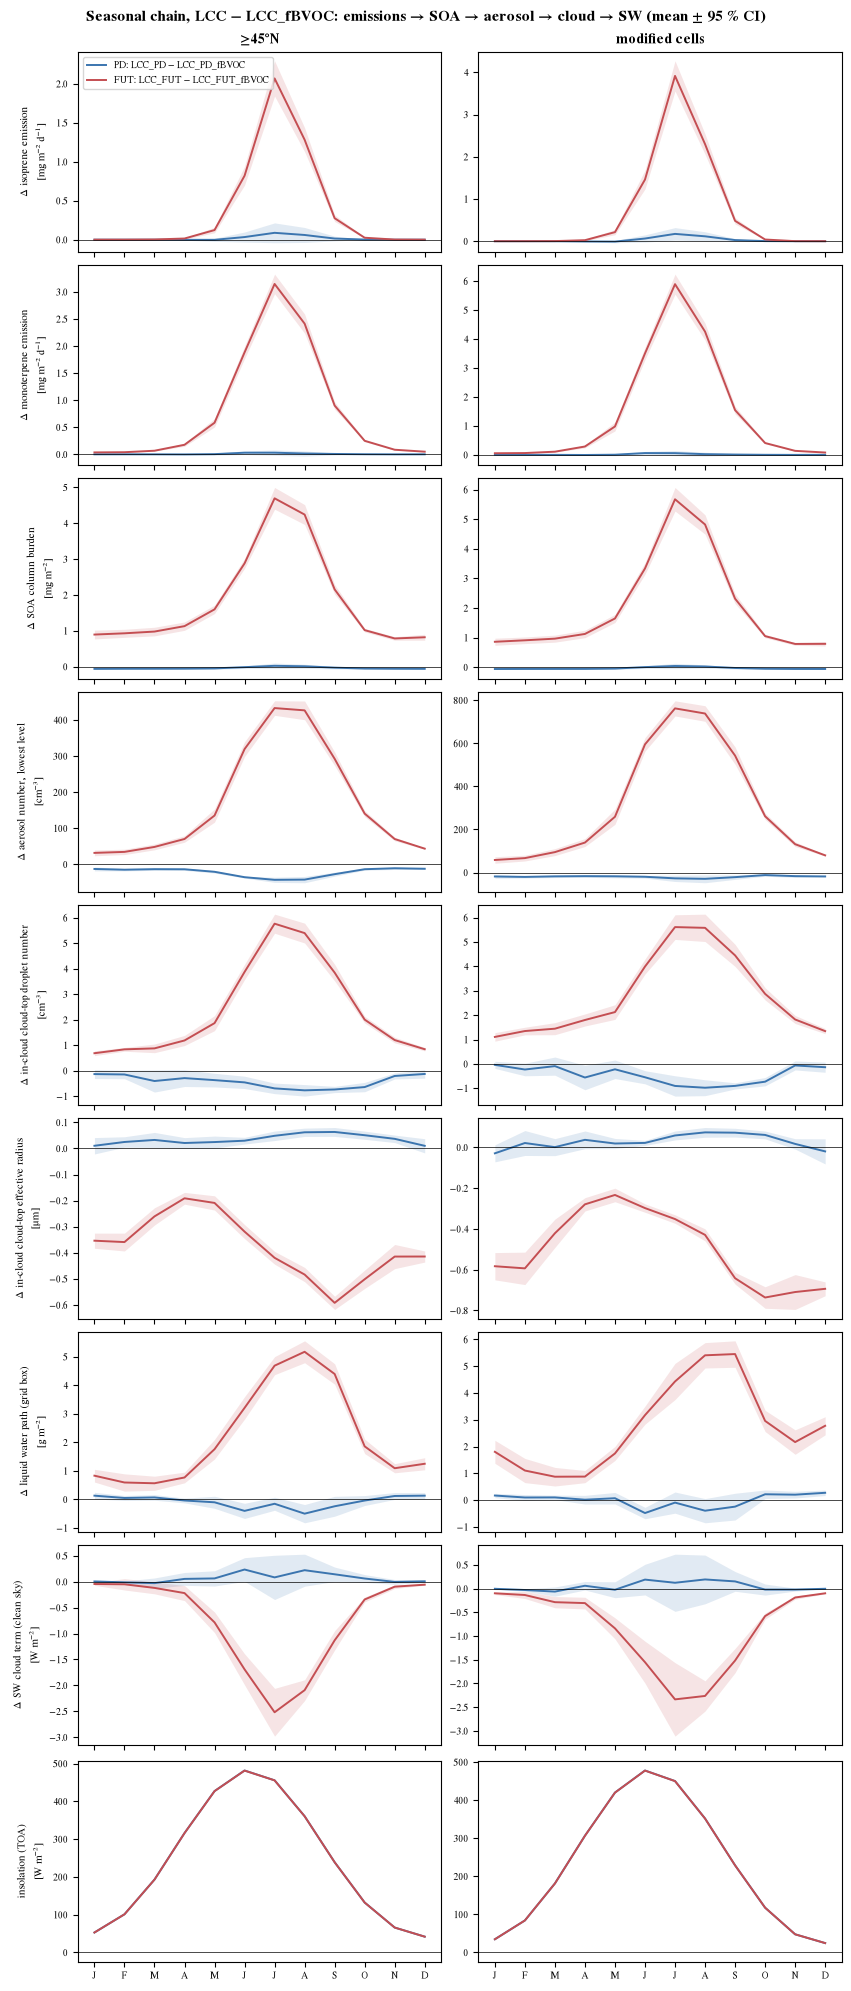

In [6]:
lines = {f"{p}: {r['lcc']} − {r['fbvoc']}": (r["lcc"], r["fbvoc"], "#3b75af" if p == "PD" else "#c44e52", "-")
         for p, r in fm.BVOC_PAIRS.items()}
fig, axes = fm.make_monthly_chain_figure(
    ["SFISOP", "SFMTERP", "SOA_cb", "N_AER", "ACTNL_incld", "ACTREL_incld", "TGCLDLWP", "SW_cre_clean"],
    ["≥45°N", "modified cells"], lines, "seasonal_chain_bvoc_soa_cloud_sw",
    "Seasonal chain, LCC − LCC_fBVOC: emissions → SOA → aerosol → cloud → SW (mean ± 95 % CI)",
    context="SOLIN", start_year=START_YEAR, end_year=END_YEAR)
plt.show(); plt.close(fig)

## D. Baseline state and relative changes
Is the FUT response larger because the perturbation is larger, because the background is more responsive, or both?
Table: CTRL and fBVOC baselines (≥45°N, annual and JJA), the CTRL FUT − PD change, and the BVOC contrast as % of its fBVOC baseline. Regional means of in-cloud quantities are means of the in-cloud maps.
Maps: (LCC − fBVOC) / fBVOC baseline in %, blank where the baseline is near zero (thresholds in `fm.PERCENT_PANELS`).

In [7]:
base = fm.baseline_table(start_year=START_YEAR, end_year=END_YEAR)
base.to_csv(TABLES / f"baseline_aerosol_cloud_{START_YEAR}_{END_YEAR}.csv", index=False)
base.round(3)

,variable,units,season,CTRL_PD,CTRL_FUT,CTRL_FUT−PD,CTRL_FUT−PD_%,fBVOC_PD,BVOC_PD,BVOC_PD_%,fBVOC_FUT,BVOC_FUT,BVOC_FUT_%
0,SOA_cb_mgm2,mg m-2,ANN,1.297,3.779,2.482,191.301,1.333,-0.039,-2.944,1.331,1.852,139.150
1,SOA_cb_mgm2,mg m-2,JJA,2.119,7.171,5.051,238.377,2.127,0.006,0.279,2.261,3.951,174.688
2,N_AER,cm-3,ANN,1003.797,857.389,-146.408,-14.585,1029.958,-21.766,-2.113,674.697,171.397,25.404
3,N_AER,cm-3,JJA,1356.852,1711.961,355.110,26.172,1405.735,-40.384,-2.873,1286.023,393.874,30.627
4,CCN3,cm-3,ANN,41.565,41.433,-0.132,-0.317,41.667,-0.046,-0.110,38.020,4.062,10.684
5,CCN3,cm-3,JJA,56.525,78.395,21.870,38.691,56.724,-0.244,-0.430,64.968,12.966,19.958
6,ACTNL_incld,cm-3,ANN,41.738,30.567,-11.171,-26.764,42.258,-0.533,-1.262,27.373,2.811,10.269
7,ACTNL_incld,cm-3,JJA,47.359,48.921,1.562,3.298,47.911,-0.677,-1.413,43.194,4.858,11.246
8,ACTREL_incld,µm,ANN,11.286,12.380,1.094,9.694,11.242,0.040,0.360,12.832,-0.422,-3.290
9,ACTREL_incld,µm,JJA,11.274,11.226,-0.048,-0.423,11.227,0.048,0.423,11.662,-0.399,-3.421


findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/bvoc_percent_change_maps_2001_2009.png


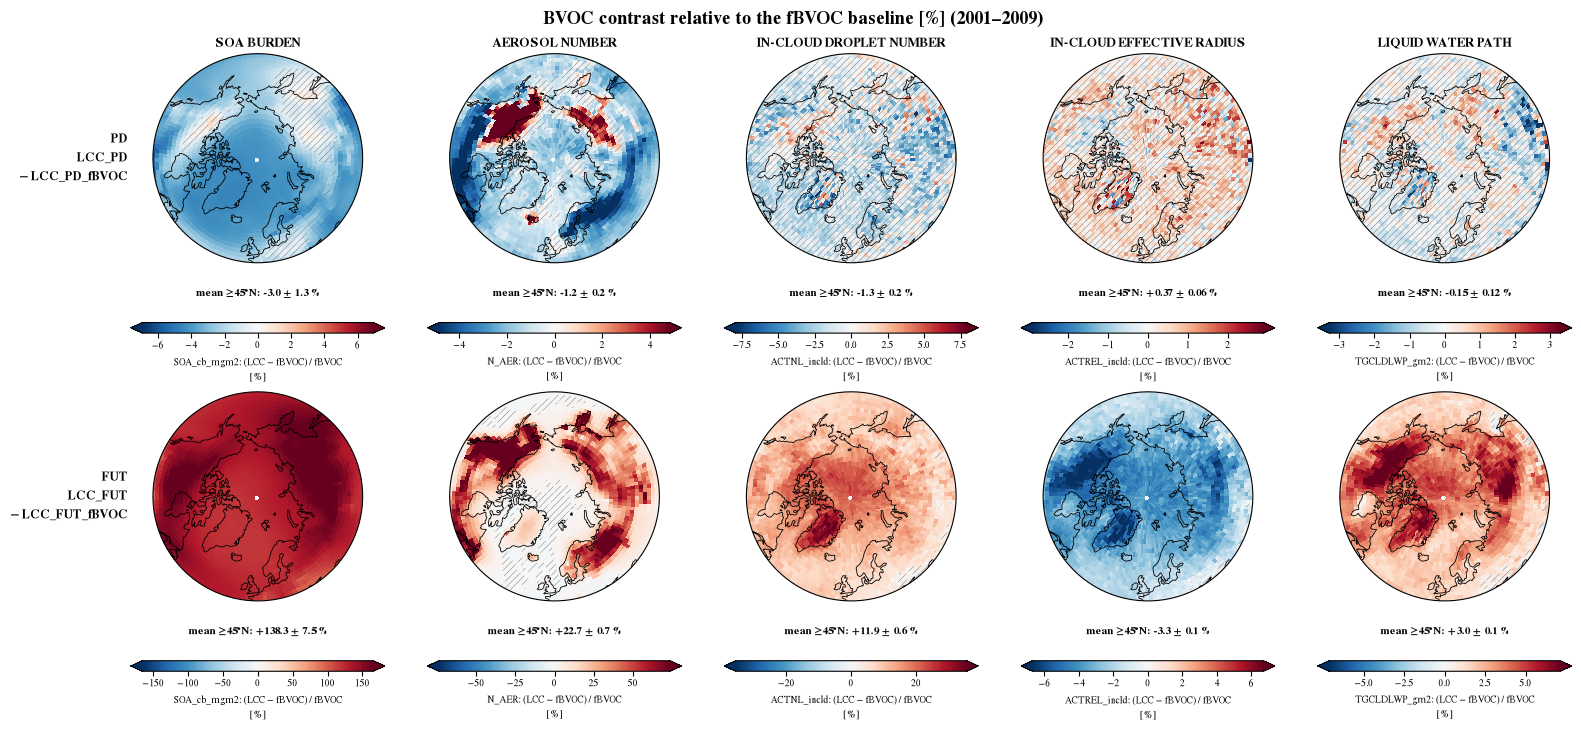

In [8]:
fig, axes = fm.make_percent_change_figure(START_YEAR, END_YEAR)
plt.show(); plt.close(fig)

## E. Paired yearly regional means
Each dot is one year's ≥45°N mean difference; the diamond is the mean ± 95 % t-interval. Shows whether a mean (e.g. the weak PD warming, or the PD–FUT contrast) is consistent across years or driven by a few.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/paired_years_NET_2001_2009.png


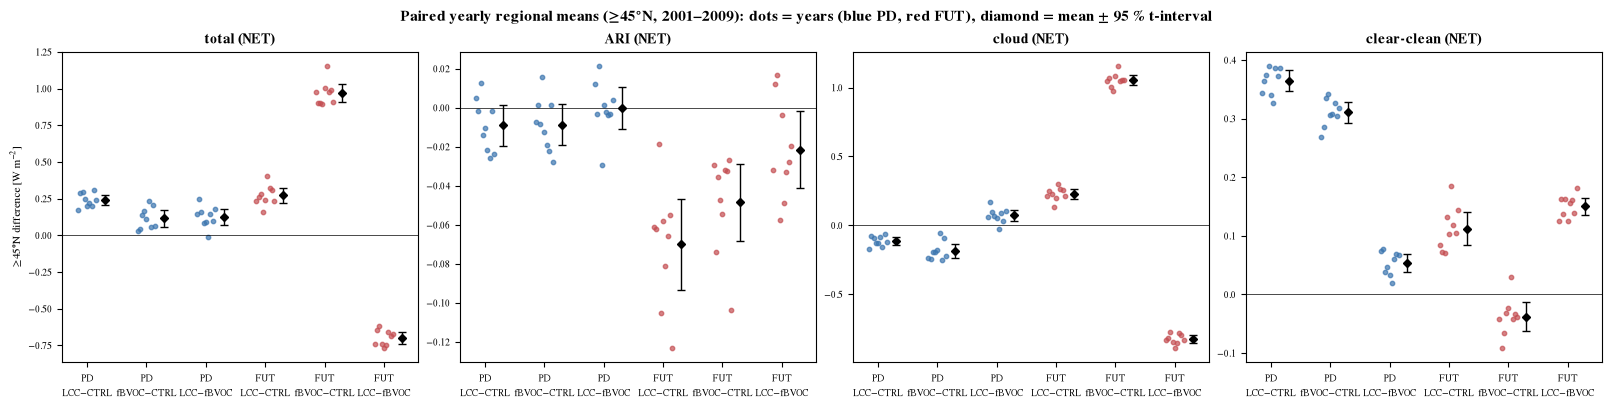

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/paired_years_SW_2001_2009.png


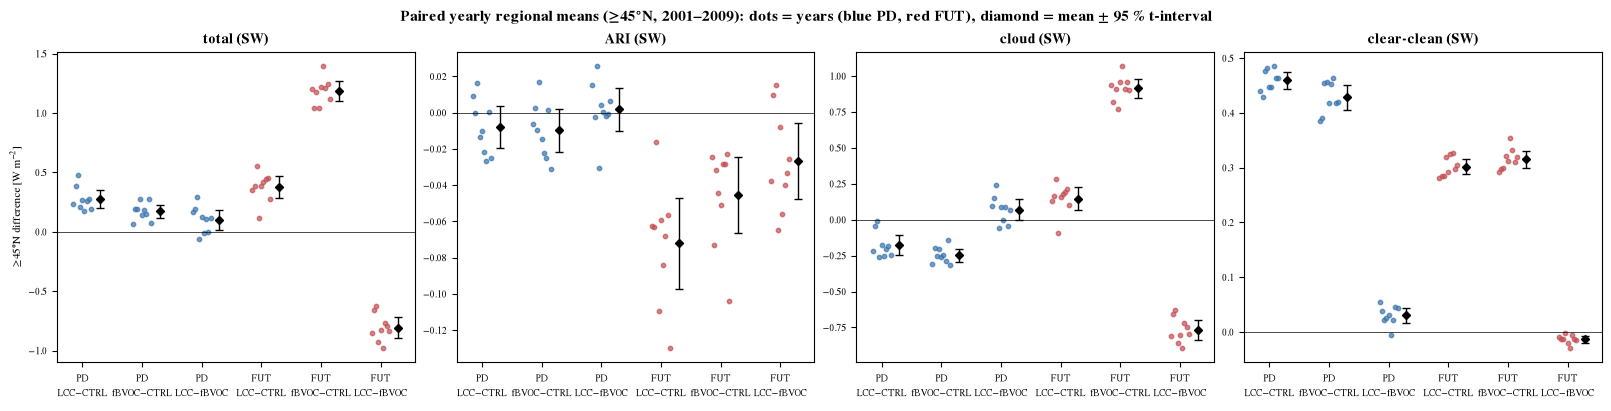

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/paired_years_LW_2001_2009.png


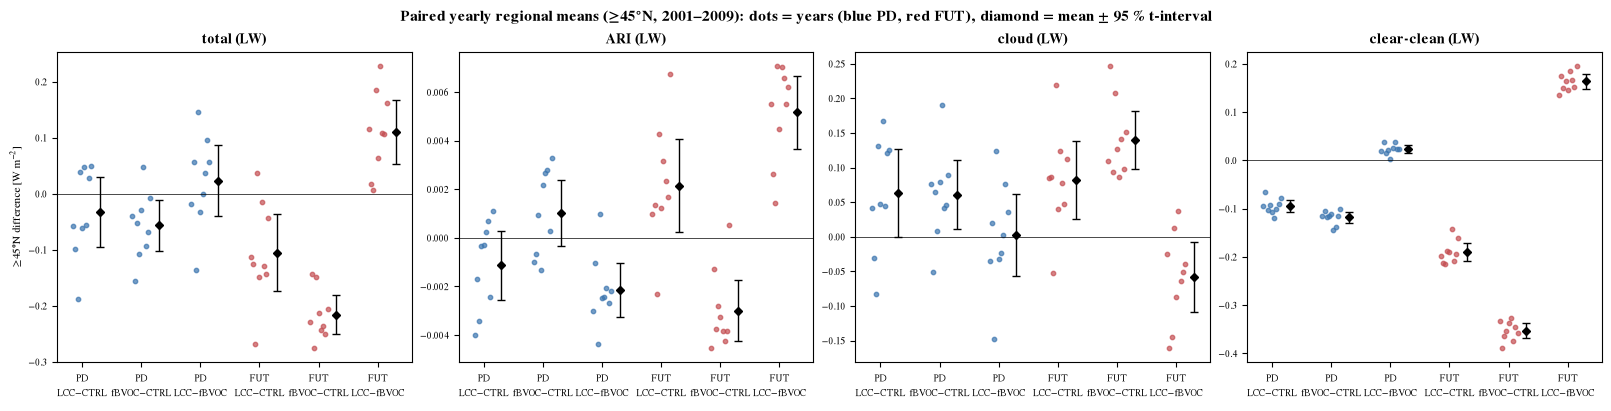

In [9]:
for band in ("NET", "SW", "LW"):
    fig, axes = fm.make_paired_years_figure(budget, band=band, start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)

## F. PD mechanism: emissions up, SOA and aerosol number down?
PD has slightly higher ≥45°N isoprene and monoterpene emissions in LCC than in fBVOC, but lower SOA burden and aerosol number. Monthly differences in four source boxes test whether SOA falls where and when its precursors rise, or whether the annual mean hides seasonal or regional compensation.
Solid = LCC_PD − LCC_PD_fBVOC (± 95 % CI), dashed = LCC_PD − CTRL_PD. Box means over all cells (land + ocean).
Boxes: Alaska/W Canada 50–72°N 190–245°E; E Canada 45–65°N 245–300°E; Europe 45–72°N 350–60°E; Siberia 50–75°N 60–190°E.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/pd_mechanism_source_boxes_2001_2009.png


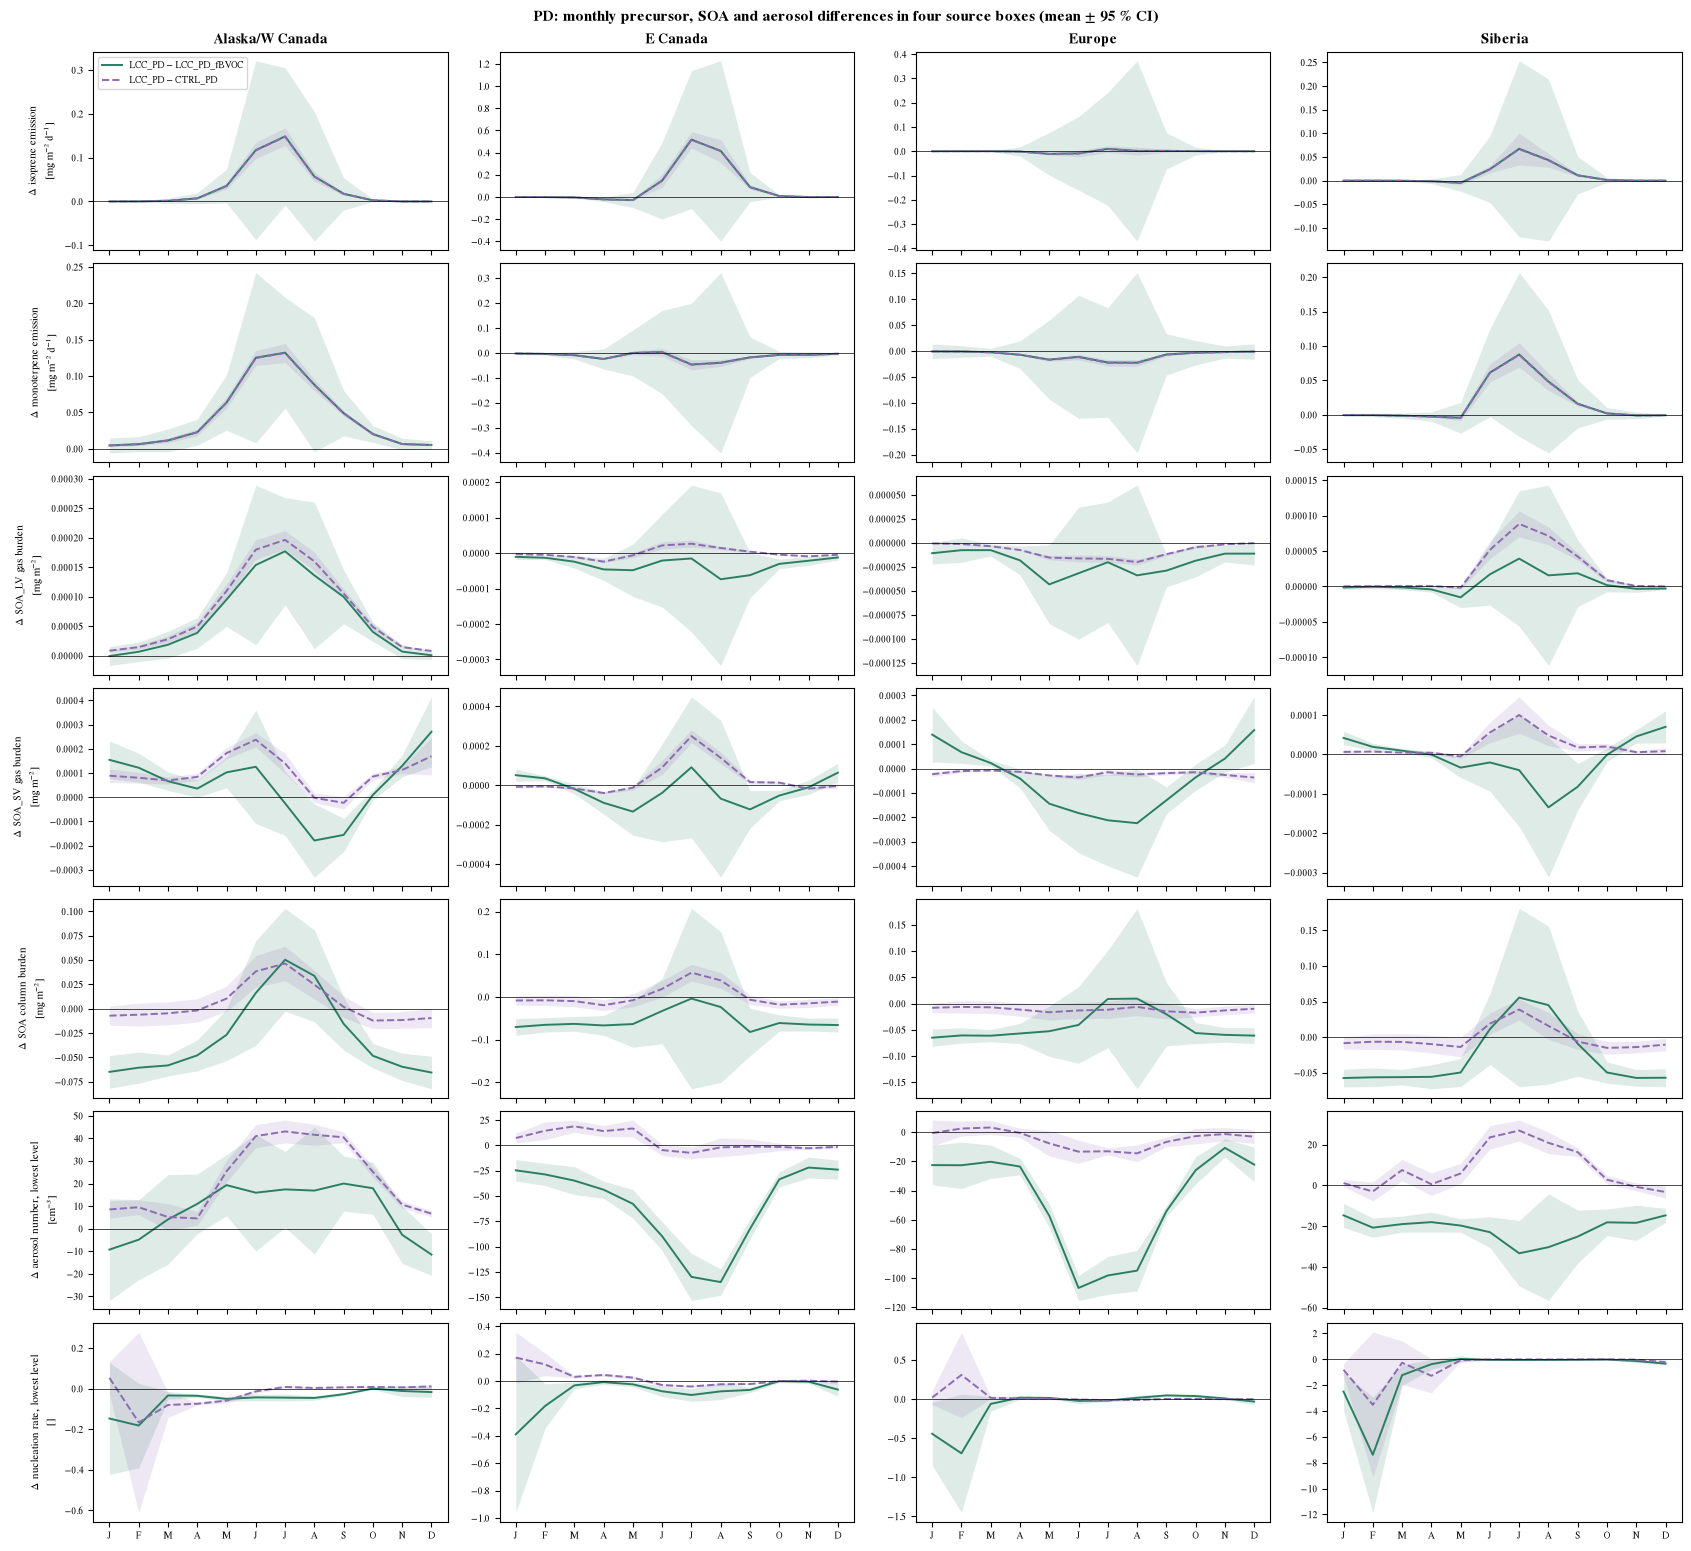

In [10]:
pd_ = fm.BVOC_PAIRS["PD"]
lines = {f"{pd_['lcc']} − {pd_['fbvoc']}": (pd_["lcc"], pd_["fbvoc"], "#2a7f62", "-"),
         f"{pd_['lcc']} − {pd_['ctrl']}": (pd_["lcc"], pd_["ctrl"], "#8c6bb1", "--")}
fig, axes = fm.make_monthly_chain_figure(
    ["SFISOP", "SFMTERP", "cb_SOA_LV", "cb_SOA_SV", "SOA_cb", "N_AER", "NUCLRATE"],
    list(fm.SOURCE_BOXES), lines, "pd_mechanism_source_boxes",
    "PD: monthly precursor, SOA and aerosol differences in four source boxes (mean ± 95 % CI)",
    start_year=START_YEAR, end_year=END_YEAR, boxes=True)
plt.show(); plt.close(fig)